# Регуляризация в регрессии

**Регуляризация** метод предотвращение переобучения (overfitting) путем штрафа за большие коэффициенты.

## Lasso (L1) Regression - Least Absolute Shrinkage and Selection Operator
Штраф: сумма модулей весов
$$
min(\sum({y-\hat{y})}^2 + \lambda\sum|w_i|)
$$

Эффект:
* может занулить коэффициенты
* Делает feature selection
## Ridge (L2) Regression
Штраф: сумма квадратов весов
$$
min(\sum(y-\hat{y})^2 + \lambda\sum w_i^2)
$$

Эффект:
* уменьшает веса
* **Не** зануляет признаки
* дает стабильную модель
## Elastic Net (L1 + L2) Regression
$$
L = MSE + \alpha\left(r\sum|w_i| + \frac{1-r}{2}\sum w_i^2\right)
$$

## Когда что использовать

| Модель               | Когда                                             |
|----------------------|---------------------------------------------------|
| Lasso (L1)           | Надо выбирать важные признаки                     |
| Ridge (L2)           | Много признаков, нужны все                        |
| ElasticNet (L1 + L2) | Смесь L1 и L2, полезно при коррелированных данных |

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

In [15]:
np.random.seed(42)
n = 120
X = np.linspace(-4, 6, n).reshape(-1, 1)
noise = np.random.normal(0, 6, n)
y = 0.5 * X.flatten() ** 3 - 3 * X.flatten() ** 2 + 2 * X.flatten() + noise


In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
len(X_train), len(X_test)

(90, 30)

In [17]:
def train_model(model, name):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    print(f'''
==== {name} ====
R2 score: {r2_score(y_test, y_pred):.2f}
RMSE    : {root_mean_squared_error(y_test, y_pred):.2f}
''')
    return model

In [20]:
degree = 10
lasso = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=0.5, max_iter=1000)),
])

ridge = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge', Ridge(alpha=1.0)),
])

elastic_net = Pipeline([
    ('poly', PolynomialFeatures(degree=degree, include_bias=False)),
    ('scaler', StandardScaler()),
    ('elastic_net', ElasticNet(alpha=0.05, max_iter=1000, l1_ratio=0.3)),
])

lasso = train_model(lasso, 'lasso')
ridge = train_model(ridge, 'ridge')
elastic_net = train_model(elastic_net, 'elastic_net')


==== lasso ====
R2 score: 0.94
RMSE    : 6.16


==== ridge ====
R2 score: 0.95
RMSE    : 5.61


==== elastic_net ====
R2 score: 0.93
RMSE    : 6.51



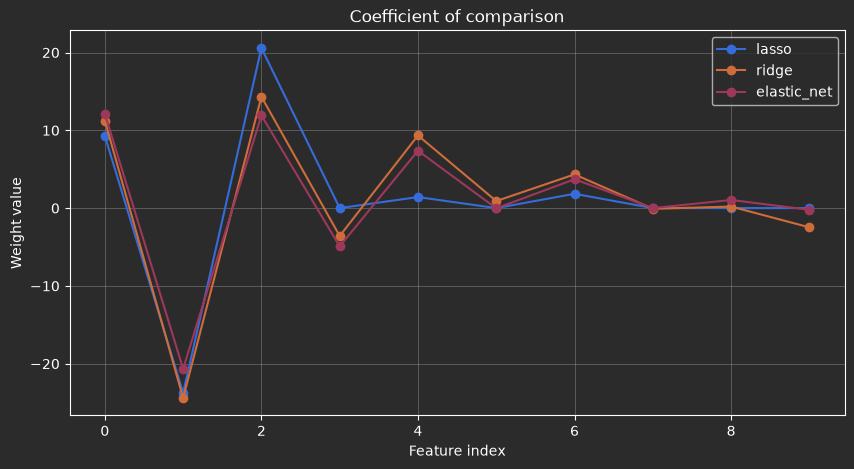

In [24]:
models = {
    'lasso': lasso.named_steps['lasso'].coef_,
    'ridge': ridge.named_steps['ridge'].coef_,
    'elastic_net': elastic_net.named_steps['elastic_net'].coef_,
}

plt.figure(figsize=(10, 5))
for name, coef in models.items():
    plt.plot(coef, label=name, marker='o')
plt.title('Coefficient of comparison')
plt.xlabel('Feature index')
plt.ylabel('Weight value')
plt.legend()
plt.grid(True)
plt.show()